# Exercice 3 — Deep Q-Network (DQN) sur CartPole-v1

## Partie 1 — DQN à la main avec PyTorch

### Étape 1 — Les classes `DQN` et `ReplayBuffer`

In [1]:
import random
from collections import deque, namedtuple

import gymnasium as gym
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 0
random.seed(SEED)
torch.manual_seed(SEED)

env = gym.make("CartPole-v1")

n_observations = env.observation_space.shape[0]
n_actions = env.action_space.n

print("Taille de l'observation :", n_observations)
print("Nombre d'actions        :", n_actions)

Taille de l'observation : 4
Nombre d'actions        : 2


#### Le réseau de neurones `DQN`

Il remplace la Q-table : il reçoit une observation et renvoie une valeur Q par action.

In [2]:
class DQN(nn.Module):
    def __init__(self, n_observations, n_actions, hidden_size=128):
        super().__init__()
        self.fc1 = nn.Linear(n_observations, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, n_actions)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

In [3]:
policy_net = DQN(n_observations, n_actions)

print(policy_net)
print("\nNombre de paramètres :", sum(p.numel() for p in policy_net.parameters()))

DQN(
  (fc1): Linear(in_features=4, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=2, bias=True)
)

Nombre de paramètres : 17410


In [4]:
obs, info = env.reset(seed=SEED)
obs_tensor = torch.as_tensor(obs, dtype=torch.float32)

with torch.no_grad():
    q_values = policy_net(obs_tensor)

print("Observation        :", obs)
print("Valeurs Q (g, d)   :", q_values.numpy())
print("Action choisie     :", q_values.argmax().item())

Observation        : [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
Valeurs Q (g, d)   : [ 0.01261492 -0.04845239]
Action choisie     : 0


#### La mémoire `ReplayBuffer`

Elle stocke les transitions vécues et en redonne un lot tiré au hasard pour l'entraînement.

In [5]:
Transition = namedtuple("Transition", ["state", "action", "reward", "next_state", "done"])


class ReplayBuffer:
    def __init__(self, capacity):
        self.memory = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.memory.append(Transition(state, action, reward, next_state, done))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

In [6]:
# Test : on remplit un petit buffer avec un agent aléatoire
buffer = ReplayBuffer(capacity=5)
env.action_space.seed(SEED)

state, info = env.reset(seed=SEED)
for _ in range(8):
    action = env.action_space.sample()
    next_state, reward, terminated, truncated, info = env.step(action)
    buffer.push(state, action, reward, next_state, terminated)
    state = next_state

print("8 transitions ajoutées, taille du buffer :", len(buffer), "(capacité 5)\n")

for transition in buffer.sample(batch_size=2):
    print(transition)

8 transitions ajoutées, taille du buffer : 5 (capacité 5)

Transition(state=array([ 0.04627601, -0.01722973, -0.10938502, -0.17705095], dtype=float32), action=np.int64(0), reward=1.0, next_state=array([ 0.04593142, -0.21063012, -0.11292604,  0.07922072], dtype=float32), done=False)
Transition(state=array([ 0.04593142, -0.21063012, -0.11292604,  0.07922072], dtype=float32), action=np.int64(0), reward=1.0, next_state=array([ 0.04171882, -0.40396732, -0.11134163,  0.33424965], dtype=float32), done=False)


### Étape 2 — La boucle d'entraînement du DQN

#### Hyperparamètres

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import torch.optim as optim

N_EPISODES = 400
BATCH_SIZE = 64            # nombre de transitions tirées de la mémoire à chaque mise à jour
GAMMA = 0.99               # facteur d'actualisation (discount factor)
LEARNING_RATE = 5e-4       # pas d'apprentissage de l'optimiseur
BUFFER_CAPACITY = 10_000   # taille de la mémoire de replay
TARGET_UPDATE_EVERY = 200  # on recopie policy_net -> target_net tous les 200 pas

EPS_START = 1.0            # epsilon au début (100 % d'exploration)
EPS_END = 0.01             # plancher d'exploration
EPS_DECAY = 0.98           # epsilon est multiplié par ce facteur après chaque épisode

#### Les deux réseaux, l'optimiseur et la mémoire

- `policy_net` : le réseau qu'on entraîne et qui choisit les actions.
- `target_net` : une copie figée, utilisée seulement pour calculer la cible.

In [8]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
env.action_space.seed(SEED)

policy_net = DQN(n_observations, n_actions)
target_net = DQN(n_observations, n_actions)
target_net.load_state_dict(policy_net.state_dict())  # mêmes poids au départ

optimizer = optim.Adam(policy_net.parameters(), lr=LEARNING_RATE)
memory = ReplayBuffer(BUFFER_CAPACITY)

#### Sélection d'action (epsilon-greedy)

In [9]:
def select_action(state, epsilon):
    # Exploration : action aléatoire avec une probabilité epsilon
    if random.random() < epsilon:
        return int(env.action_space.sample())

    # Exploitation : action dont la valeur Q prédite est la plus grande
    with torch.no_grad():
        state_tensor = torch.FloatTensor(state).unsqueeze(0)  # forme (4,) -> (1, 4)
        q_values = policy_net(state_tensor)                   # forme (1, 2)
        return q_values.argmax(1).item()

#### `optimize_model()` : une étape d'apprentissage

$$\text{cible} = r + \gamma \, \max_{a'} Q_{\text{target}}(s', a') \qquad \text{perte} = \text{écart entre } Q_{\text{policy}}(s, a) \text{ et la cible}$$

In [10]:
def optimize_model():
    # On attend d'avoir assez de transitions pour former un lot
    if len(memory) < BATCH_SIZE:
        return

    # 1. Tirer un lot au hasard et regrouper les champs :
    #    liste de Transition -> une Transition de tuples (tous les états, toutes les actions...)
    transitions = memory.sample(BATCH_SIZE)
    batch = Transition(*zip(*transitions))

    # 2. Convertir en tenseurs PyTorch
    states = torch.FloatTensor(np.array(batch.state))            # (64, 4)
    actions = torch.LongTensor(batch.action).unsqueeze(1)        # (64,) -> (64, 1)
    rewards = torch.FloatTensor(batch.reward)                    # (64,)
    next_states = torch.FloatTensor(np.array(batch.next_state))  # (64, 4)
    dones = torch.FloatTensor(batch.done)                        # (64,)  1.0 si épisode terminé

    # 3. Valeurs Q prédites par policy_net pour les actions réellement jouées
    #    policy_net(states) -> (64, 2) ; gather garde, sur chaque ligne, la colonne de l'action jouée
    q_values = policy_net(states).gather(1, actions).squeeze(1)  # (64,)

    # 4. Valeurs Q cibles, calculées avec target_net (sans gradient)
    #    .max(1) renvoie (valeurs, indices) ; [0] garde les valeurs
    with torch.no_grad():
        max_next_q = target_net(next_states).max(1)[0]           # (64,)
    #    (1 - dones) annule la partie future quand l'épisode est terminé
    target_q_values = rewards + GAMMA * max_next_q * (1 - dones)

    # 5. Perte : écart entre les prédictions et les cibles
    loss = F.smooth_l1_loss(q_values, target_q_values)

    # 6. Optimisation : on corrige les poids de policy_net
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(policy_net.parameters(), max_norm=10)
    optimizer.step()

#### La boucle d'entraînement

In [11]:
epsilon = EPS_START
episode_rewards = []
total_steps = 0

for episode in range(N_EPISODES):
    state, info = env.reset(seed=SEED + episode)
    total_reward = 0.0
    terminated = truncated = False

    while not (terminated or truncated):
        # L'agent agit et on enregistre la transition dans la mémoire
        action = select_action(state, epsilon)
        next_state, reward, terminated, truncated, info = env.step(action)
        memory.push(state, action, reward, next_state, float(terminated))

        state = next_state
        total_reward += reward
        total_steps += 1

        # Une étape d'apprentissage sur un lot tiré de la mémoire
        optimize_model()

        # Mise à jour périodique du target network
        if total_steps % TARGET_UPDATE_EVERY == 0:
            target_net.load_state_dict(policy_net.state_dict())

    epsilon = max(EPS_END, epsilon * EPS_DECAY)
    episode_rewards.append(total_reward)

    if (episode + 1) % 50 == 0:
        moyenne = np.mean(episode_rewards[-50:])
        print(f"Épisode {episode + 1:>3} | epsilon = {epsilon:.3f} | récompense moyenne (50 derniers) = {moyenne:.1f}")

Épisode  50 | epsilon = 0.364 | récompense moyenne (50 derniers) = 64.7


Épisode 100 | epsilon = 0.133 | récompense moyenne (50 derniers) = 201.2


Épisode 150 | epsilon = 0.048 | récompense moyenne (50 derniers) = 396.2


Épisode 200 | epsilon = 0.018 | récompense moyenne (50 derniers) = 324.4


Épisode 250 | epsilon = 0.010 | récompense moyenne (50 derniers) = 251.9


Épisode 300 | epsilon = 0.010 | récompense moyenne (50 derniers) = 468.7


Épisode 350 | epsilon = 0.010 | récompense moyenne (50 derniers) = 346.0


Épisode 400 | epsilon = 0.010 | récompense moyenne (50 derniers) = 358.8


#### Courbe des récompenses par épisode

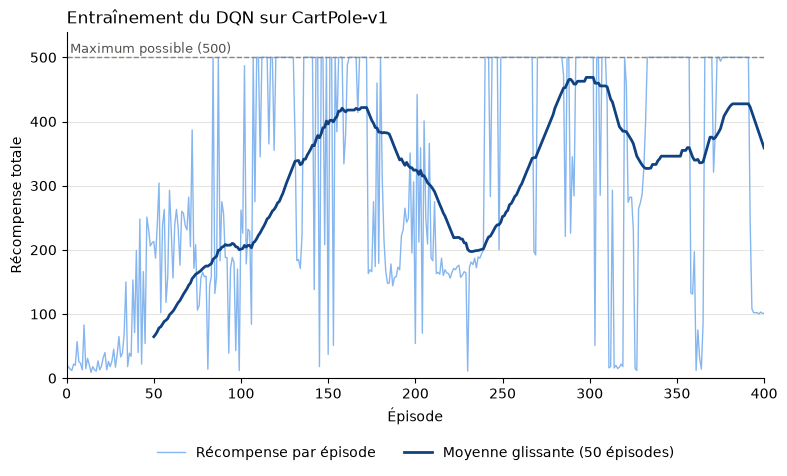

In [12]:
FENETRE = 50
episodes = np.arange(1, N_EPISODES + 1)
moyenne_glissante = np.convolve(episode_rewards, np.ones(FENETRE) / FENETRE, mode="valid")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(episodes, episode_rewards, color="#86b6ef", linewidth=1, label="Récompense par épisode")
ax.plot(episodes[FENETRE - 1:], moyenne_glissante, color="#104281", linewidth=2,
        label=f"Moyenne glissante ({FENETRE} épisodes)")
ax.axhline(500, color="#898781", linewidth=1, linestyle="--")
ax.text(2, 507, "Maximum possible (500)", color="#52514e", fontsize=9)

ax.set_title("Entraînement du DQN sur CartPole-v1", loc="left")
ax.set_xlabel("Épisode")
ax.set_ylabel("Récompense totale")
ax.set_ylim(0, 540)
ax.set_xlim(0, N_EPISODES)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
plt.show()

## Partie 2 — DQN avec Stable-Baselines3

### Étape 3 — Entraîner, évaluer et sauvegarder

La classe `DQN` de SB3 est importée sous le nom `SB3DQN` pour ne pas écraser notre classe `DQN` de la partie 1 (qui n'est que le réseau de neurones).

In [13]:
from stable_baselines3 import DQN as SB3DQN
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor

TOTAL_TIMESTEPS = 25_000  # nombre de pas (appels à env.step), pas d'épisodes

train_env = gym.make("CartPole-v1")
eval_env = Monitor(gym.make("CartPole-v1"))  # Monitor enregistre la récompense de chaque épisode

#### Essai 1 — hyperparamètres par défaut de SB3

In [14]:
model_defaut = SB3DQN("MlpPolicy", train_env, verbose=1, tensorboard_log="./logs/", seed=SEED)
model_defaut.learn(total_timesteps=TOTAL_TIMESTEPS, log_interval=400, tb_log_name="dqn_defaut")

mean_reward, std_reward = evaluate_policy(model_defaut, eval_env, n_eval_episodes=100)
print(f"\nRécompense moyenne sur 100 épisodes : {mean_reward:.1f} +/- {std_reward:.1f}")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./logs/dqn_defaut_1


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 9.61     |
|    ep_rew_mean      | 9.61     |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 400      |
|    fps              | 2600     |
|    time_elapsed     | 1        |
|    total_timesteps  | 4667     |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.00302  |
|    n_updates        | 1141     |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 9.52     |
|    ep_rew_mean      | 9.52     |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 800      |
|    fps              | 2512     |
|    time_elapsed     | 3        |
|    total_timesteps  | 8548     |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.00189  |
|    n_updates        | 2111     |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 9.62     |
|    ep_rew_mean      | 9.62     |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 1200     |
|    fps              | 2469     |
|    time_elapsed     | 5        |
|    total_timesteps  | 12408    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.0303   |
|    n_updates        | 3076     |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 9.38     |
|    ep_rew_mean      | 9.38     |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 1600     |
|    fps              | 2454     |
|    time_elapsed     | 6        |
|    total_timesteps  | 16199    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.0204   |
|    n_updates        | 4024     |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 9.81     |
|    ep_rew_mean      | 9.81     |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 2000     |
|    fps              | 2444     |
|    time_elapsed     | 8        |
|    total_timesteps  | 20063    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.17     |
|    n_updates        | 4990     |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 9.51     |
|    ep_rew_mean      | 9.51     |
|    exploration_rate | 0.05     |
| time/               |          |
|    episodes         | 2400     |
|    fps              | 2431     |
|    time_elapsed     | 9        |
|    total_timesteps  | 23913    |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.0551   |
|    n_updates        | 5953     |
----------------------------------



Récompense moyenne sur 100 épisodes : 9.3 +/- 0.8


#### Essai 2 — les hyperparamètres de notre DQN manuel

Chaque argument correspond à une constante de la partie 1.

In [15]:
model = SB3DQN(
    "MlpPolicy",
    train_env,
    learning_rate=5e-4,                         # LEARNING_RATE
    buffer_size=10_000,                         # BUFFER_CAPACITY
    batch_size=64,                              # BATCH_SIZE
    gamma=0.99,                                 # GAMMA
    learning_starts=64,                         # on apprend dès qu'un lot est disponible
    train_freq=1,                               # une mise à jour à chaque pas
    target_update_interval=200,                 # TARGET_UPDATE_EVERY
    exploration_fraction=0.2,                   # epsilon décroît pendant les premiers 20 % des pas
    exploration_final_eps=0.01,                 # EPS_END
    policy_kwargs=dict(net_arch=[128, 128]),    # deux couches cachées de 128 neurones
    verbose=1,
    tensorboard_log="./logs/",
    seed=SEED,
)
model.learn(total_timesteps=TOTAL_TIMESTEPS, log_interval=25, tb_log_name="dqn_regle")

mean_reward, std_reward = evaluate_policy(model, eval_env, n_eval_episodes=100)
print(f"\nRécompense moyenne sur 100 épisodes : {mean_reward:.1f} +/- {std_reward:.1f}")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./logs/dqn_regle_1


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 25.8     |
|    ep_rew_mean      | 25.8     |
|    exploration_rate | 0.872    |
| time/               |          |
|    episodes         | 25       |
|    fps              | 973      |
|    time_elapsed     | 0        |
|    total_timesteps  | 645      |
| train/              |          |
|    learning_rate    | 0.0005   |
|    loss             | 0.0283   |
|    n_updates        | 580      |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 34.1     |
|    ep_rew_mean      | 34.1     |
|    exploration_rate | 0.662    |
| time/               |          |
|    episodes         | 50       |
|    fps              | 911      |
|    time_elapsed     | 1        |
|    total_timesteps  | 1705     |
| train/              |          |
|    learning_rate    | 0.0005   |
|    loss             | 0.191    |
|    n_updates        | 1640     |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 66.4     |
|    ep_rew_mean      | 66.4     |
|    exploration_rate | 0.0144   |
| time/               |          |
|    episodes         | 75       |
|    fps              | 861      |
|    time_elapsed     | 5        |
|    total_timesteps  | 4978     |
| train/              |          |
|    learning_rate    | 0.0005   |
|    loss             | 0.103    |
|    n_updates        | 4913     |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 100      |
|    ep_rew_mean      | 100      |
|    exploration_rate | 0.01     |
| time/               |          |
|    episodes         | 100      |
|    fps              | 835      |
|    time_elapsed     | 11       |
|    total_timesteps  | 10002    |
| train/              |          |
|    learning_rate    | 0.0005   |
|    loss             | 0.122    |
|    n_updates        | 9937     |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 129      |
|    ep_rew_mean      | 129      |
|    exploration_rate | 0.01     |
| time/               |          |
|    episodes         | 125      |
|    fps              | 828      |
|    time_elapsed     | 16       |
|    total_timesteps  | 13504    |
| train/              |          |
|    learning_rate    | 0.0005   |
|    loss             | 0.519    |
|    n_updates        | 13439    |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 154      |
|    ep_rew_mean      | 154      |
|    exploration_rate | 0.01     |
| time/               |          |
|    episodes         | 150      |
|    fps              | 824      |
|    time_elapsed     | 20       |
|    total_timesteps  | 17070    |
| train/              |          |
|    learning_rate    | 0.0005   |
|    loss             | 0.0267   |
|    n_updates        | 17005    |
----------------------------------


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 173      |
|    ep_rew_mean      | 173      |
|    exploration_rate | 0.01     |
| time/               |          |
|    episodes         | 175      |
|    fps              | 821      |
|    time_elapsed     | 27       |
|    total_timesteps  | 22235    |
| train/              |          |
|    learning_rate    | 0.0005   |
|    loss             | 0.0887   |
|    n_updates        | 22170    |
----------------------------------



Récompense moyenne sur 100 épisodes : 500.0 +/- 0.0


#### Sauvegarde et rechargement du modèle

In [16]:
model.save("dqn_cartpole")  # crée dqn_cartpole.zip

loaded_model = SB3DQN.load("dqn_cartpole")
mean_reward, std_reward = evaluate_policy(loaded_model, eval_env, n_eval_episodes=100)
print(f"Modèle rechargé — récompense moyenne sur 100 épisodes : {mean_reward:.1f} +/- {std_reward:.1f}")

Modèle rechargé — récompense moyenne sur 100 épisodes : 500.0 +/- 0.0


In [17]:
env.close()
train_env.close()
eval_env.close()